# Practice 05 — AutoML

**Goal:** search hyperparameters with `GridSearchCV` and Optuna, then let AutoGluon run the whole search.

| Section | Tool | Question it answers |
|:---|:---|:---|
| 1 | `GridSearchCV` | which values, which model family, from a list |
| 2 | Optuna | which values, chosen trial by trial |
| 3 | `optuna.visualization` | how did the search go, which hyperparameter mattered? |
| 4 | Optuna, conditional search space | which model family? |
| 5 | AutoGluon Tabular | the whole search, ensemble included |
| 6 | Comparison | test accuracy of the three winners |

- Data → `fetch_openml('vehicle')`: 846 vehicle silhouettes, 18 shape features each, four classes
- Install → the first code cell; about two minutes in Colab, once per session

---
## Setup and Data

In [1]:
import os
import subprocess
import sys
os.environ['OMP_NUM_THREADS'] = '1'   # one thread per process, so n_jobs=-1 below does not oversubscribe the CPU
os.environ['LOKY_MAX_CPU_COUNT'] = '4'   # worker processes for n_jobs=-1 (also silences a Windows-only core-count warning)

try:
    import optuna
    import autogluon.tabular
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'optuna', 'autogluon.tabular[lightgbm,catboost,xgboost]'], check=True)
    import optuna
    import autogluon.tabular

print(f'optuna {optuna.__version__}, autogluon {autogluon.tabular.__version__}')

optuna 5.0.0, autogluon 1.6.3


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Failed to use ray')   # AutoGluon fits folds one after another without ray
np.random.seed(42)

### The Data

- `fetch_openml('vehicle')` → the Statlog vehicle silhouettes (UCI): each row is one silhouette described by 18 shape measures, the label one of `bus`, `opel`, `saab`, `van`
- The test set is split off once and never used to choose a model

In [3]:
vehicle = fetch_openml('vehicle', version=1, as_frame=True)
X = vehicle.data
y = vehicle.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f'train   {X_train.shape}')
print(f'test    {X_test.shape}')
print('classes:', list(np.unique(y)))
vehicle.frame.head()

train   (676, 18)
test    (170, 18)
classes: ['bus', 'opel', 'saab', 'van']


,COMPACTNESS,CIRCULARITY,DISTANCE_CIRCULARITY,RADIUS_RATIO,PR.AXIS_ASPECT_RATIO,MAX.LENGTH_ASPECT_RATIO,SCATTER_RATIO,ELONGATEDNESS,PR.AXIS_RECTANGULARITY,MAX.LENGTH_RECTANGULARITY,SCALED_VARIANCE_MAJOR,SCALED_VARIANCE_MINOR,SCALED_RADIUS_OF_GYRATION,SKEWNESS_ABOUT_MAJOR,SKEWNESS_ABOUT_MINOR,KURTOSIS_ABOUT_MAJOR,KURTOSIS_ABOUT_MINOR,HOLLOWS_RATIO,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus


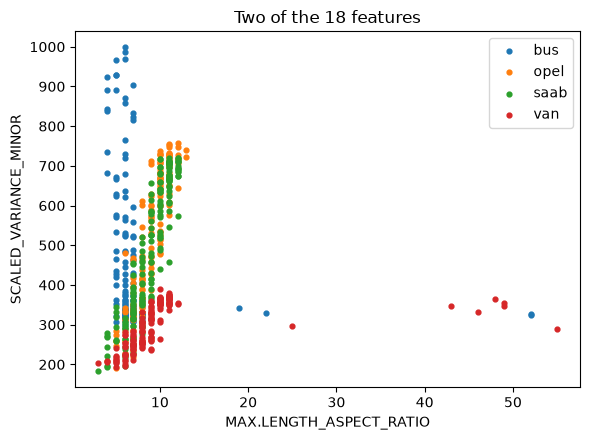

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name in np.unique(y_train):
    rows = X_train[y_train == name]
    ax.scatter(rows['MAX.LENGTH_ASPECT_RATIO'], rows['SCALED_VARIANCE_MINOR'], s=12, label=name)
ax.set_xlabel('MAX.LENGTH_ASPECT_RATIO')
ax.set_ylabel('SCALED_VARIANCE_MINOR')
ax.set_title('Two of the 18 features')
ax.legend()
plt.tight_layout()
plt.show()

- `bus` and `van` already separate on these two features; `opel` and `saab` sit on top of each other → that pair is where the models will differ

### Pipeline and Cross-Validation

- `Pipeline` → scaler + model as one estimator; refitted inside every fold, so the scaler never sees the held-out part
- The `'model'` step name gives the parameter names `model__C`, `model__gamma`
- `cv` → the same five folds for every search below

In [5]:
pipeline = Pipeline([('scaler', StandardScaler()),
                     ('model',  SVC(random_state=42))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(pipeline, X_train, y_train, cv=cv, n_jobs=-1)
acc_val_baseline = np.mean(scores)
print('fold scores :', np.round(scores, 4))
print(f'mean        : {acc_val_baseline:.4f}')

fold scores : [0.7059 0.7556 0.7778 0.7852 0.6963]
mean        : 0.7441


- Default SVC (`C=1`, `gamma='scale'`) → CV accuracy 0.744 before any tuning
- Fitted once on the whole training set → its test accuracy is the reference for the comparison at the end

In [6]:
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
acc_test_baseline = accuracy_score(y_test, y_pred)
print(f'test accuracy : {acc_test_baseline:.4f}')

test accuracy : 0.7647


---
# 1. `GridSearchCV`

- SVC has two hyperparameters that interact: `C` (penalty for a misclassified training point) and `gamma` (reach of one training point)
- A grid → every combination of the listed values, each scored with the same `cv`

In [7]:
param_grid = {'model__C': [0.1, 1, 10, 100], 'model__gamma': [1e-4, 1e-3, 1e-2, 1e-1]}

grid_search = GridSearchCV(pipeline, param_grid, cv=cv, n_jobs=-1)
grid_search.fit(X_train, y_train)

print('candidates :', len(grid_search.cv_results_['params']))
print('best params:', grid_search.best_params_)
print(f'best CV    : {grid_search.best_score_:.4f}')

candidates : 16
best params: {'model__C': 100, 'model__gamma': 0.01}
best CV    : 0.8343


### The Grid as a Map

- `mean_test_score` reshaped to 4 x 4 → rows `C`, columns `gamma`, the accuracy written in every cell

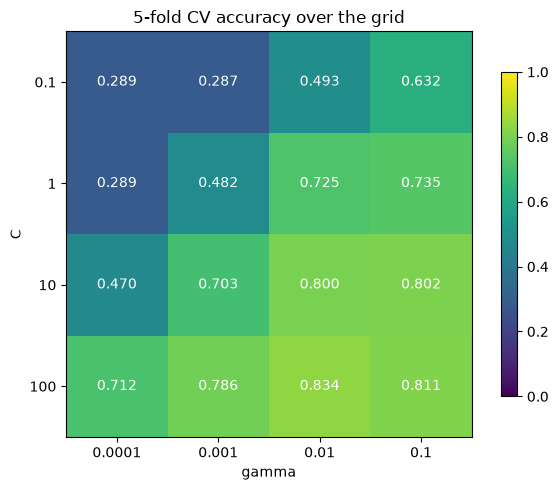

In [8]:
grid_scores = grid_search.cv_results_['mean_test_score'].reshape(4, 4)

fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(grid_scores, cmap='viridis', vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{grid_scores[i, j]:.3f}', ha='center', va='center', color='white')
ax.set_xticks(range(4), param_grid['model__gamma'])
ax.set_yticks(range(4), param_grid['model__C'])
ax.set_xlabel('gamma')
ax.set_ylabel('C')
ax.set_title('5-fold CV accuracy over the grid')
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

- 16 candidates, 80 fits → best 0.834 at `C=100`, `gamma=0.01`, nine points above the default
- The best sits on the grid's edge (`C=100` is the largest value listed) → a grid finds only what you wrote; the ridge may continue past it
- The same budget went to the empty corner (`C=0.1`: 0.29) as to the ridge

### The Model as Well

- A **list of dictionaries** → each one fixes the `model` step and lists that family's values; four families, 20 candidates in one call

In [9]:
search_space = [
    {'model': [LogisticRegression(max_iter=2000, random_state=42)],
     'model__C': [0.1, 1, 10]},
    {'model': [KNeighborsClassifier()],
     'model__n_neighbors': [1, 3, 5, 7]},
    {'model': [SVC(random_state=42)],
     'model__C': [1, 10, 100], 'model__gamma': [1e-3, 1e-2, 1e-1]},
    {'model': [RandomForestClassifier(random_state=42)],
     'model__n_estimators': [100, 300], 'model__max_depth': [None, 10]},
]

grid_search_family = GridSearchCV(pipeline, search_space, cv=cv, n_jobs=-1)
grid_search_family.fit(X_train, y_train)

y_pred = grid_search_family.predict(X_test)
print('candidates   :', len(grid_search_family.cv_results_['params']))
print('best params  :', grid_search_family.best_params_)
print(f'best CV      : {grid_search_family.best_score_:.4f}')
print(f'test accuracy: {accuracy_score(y_test, y_pred):.4f}')

candidates   : 20
best params  : {'model': SVC(random_state=42), 'model__C': 100, 'model__gamma': 0.01}
best CV      : 0.8343
test accuracy: 0.8529


- The winner is the same SVC → the best of each other family on its listed values: logistic regression 0.790, random forest 0.753, KNN 0.694
- Every candidate was written in advance → the grid cannot try a value you did not list, which is what Optuna changes

---
# 2. Optuna

- Nothing is listed → you write a function that builds and scores **one** candidate
- Optuna calls it `n_trials` times; its sampler, TPE (a form of **Bayesian optimization**), picks the next values from the scores so far

Documentation: <https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/001_first.html>

### How TPE Picks the Next Value

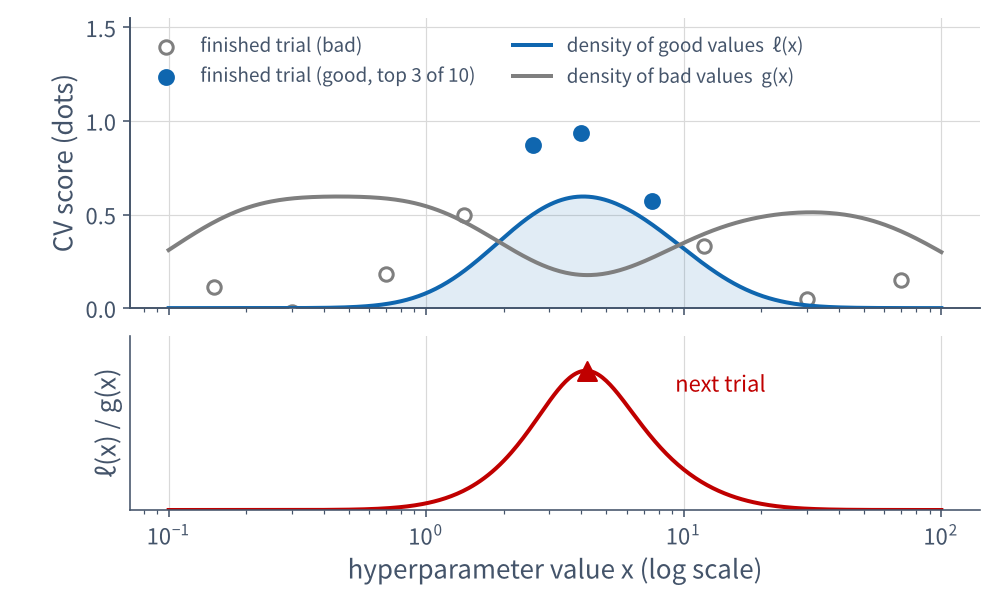

- Finished trials are split into **good** (the best few) and **bad**; a density is fitted to each → ℓ(x) and g(x)
- The next value is where ℓ(x) / g(x) is largest: likely among the good, rare among the bad; refitted after every trial
- The first 10 trials are random (`n_startup_trials`) → the material for the two densities

### `trial`, and What Is Ours

| Name | Whose |
|:---|:---|
| `trial`, `suggest_float`, `suggest_int`, `suggest_categorical`, `study`, `optimize` | Optuna's |
| `build_model`, `objective`, `'C'`, `'gamma'`, the ranges | ours |

- `trial.suggest_float('C', 0.1, 100, log=True)` → one value from the range, recorded under the name `'C'`; `log=True` samples evenly in powers of ten
- One call of `objective` = one **trial**; its return value is what the study maximizes

In [10]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


def build_model(trial):                        # values asked from the trial → a pipeline
    C = trial.suggest_float('C', 0.1, 100, log=True)
    gamma = trial.suggest_float('gamma', 1e-4, 1e-1, log=True)
    return Pipeline([('scaler', StandardScaler()),
                     ('model',  SVC(C=C, gamma=gamma, random_state=42))])


def objective(trial):                          # one trial = one candidate, scored with the same cv
    candidate = build_model(trial)
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, n_jobs=-1)
    return np.mean(scores)


study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=40)

print('trials     :', len(study.trials))
print('best params:', study.best_params)
print(f'best CV    : {study.best_value:.4f}')

trials     : 40
best params: {'C': 28.44424383866826, 'gamma': 0.031179947301804276}
best CV    : 0.8432


- Same hyperparameters and ranges as the grid; 40 trials instead of 16 → best CV 0.843 vs 0.834
- The winner is not a grid point → `C` = 28, `gamma` = 0.031; both are continuous for Optuna
- Your winner may differ a little from run to run → TPE reacts to tiny score differences, and the ridge is flat

### Predicting with the Winner

- Optuna only proposes values and records scores → nothing is fitted on the whole training set, so that one `fit` is ours
- `FixedTrial(best_params)` → a trial that answers with the best values, so `build_model` returns the winning pipeline

In [11]:
model_optuna = build_model(optuna.trial.FixedTrial(study.best_params))
model_optuna.fit(X_train, y_train)

y_pred = model_optuna.predict(X_test)
print(f'test accuracy : {accuracy_score(y_test, y_pred):.4f}')

test accuracy : 0.8588


---
# 3. Reading the Search — `optuna.visualization`

- Every trial is stored in `study.trials` → the plots below are views of that record
- `optuna.visualization.matplotlib` → static plots; `optuna.visualization` gives the same plots as interactive Plotly figures

Documentation: <https://optuna.readthedocs.io/en/stable/reference/visualization/index.html>

### Optimization History

- One point per trial, in the order they ran; the line is the best value so far

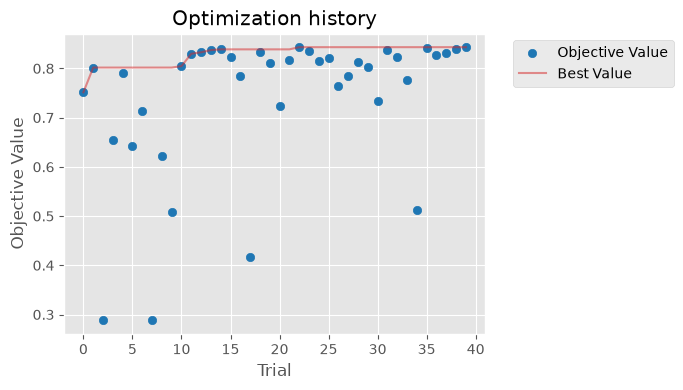

In [12]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_contour, plot_param_importances
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)

ax = plot_optimization_history(study)
ax.set_title('Optimization history')
ax.figure.set_size_inches(7, 4)
plt.tight_layout()
plt.show()

- Trials 0–9 are random start-up trials (Optuna's default `n_startup_trials=10`) → they scatter from 0.29 (small `C`) to 0.80; after that TPE stays near the top
- Which values each point stands for → `study.trials_dataframe()`, one row per trial

In [13]:
trials = study.trials_dataframe()
trials[['number', 'value', 'params_C', 'params_gamma']].round(4)

,number,value,params_C,params_gamma
0,0,0.7515,1.3293,0.0711
1,1,0.8017,15.7030,0.0063
2,2,0.2885,0.2938,0.0003
3,3,0.6538,0.1494,0.0397
4,4,0.7914,6.3584,0.0133
5,5,0.6420,0.1153,0.0812
6,6,0.7145,31.4288,0.0004
7,7,0.2885,0.3511,0.0004
8,8,0.6213,0.8179,0.0038
9,9,0.5089,1.9762,0.0007


### Contour — Where the Trials Went

- The 40 trials on the `C`–`gamma` plane; the colour between the markers is interpolated

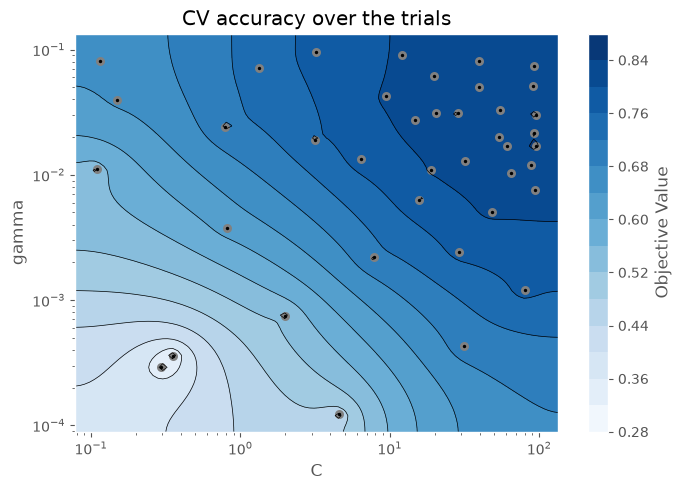

In [14]:
ax = plot_contour(study, params=['C', 'gamma'])
ax.set_title('CV accuracy over the trials')
ax.figure.set_size_inches(7, 5)
plt.tight_layout()
plt.show()

- Grid → one point per cell, 16 evenly spaced; Optuna → a few visits to small `C`, the rest crowded in the top-right corner (`C` above 10, `gamma` 0.01–0.1)
- The markers are the only measured points → read the colour between them with care

### Hyperparameter Importance

- `plot_param_importances` → how much each hyperparameter moved the CV accuracy across the trials

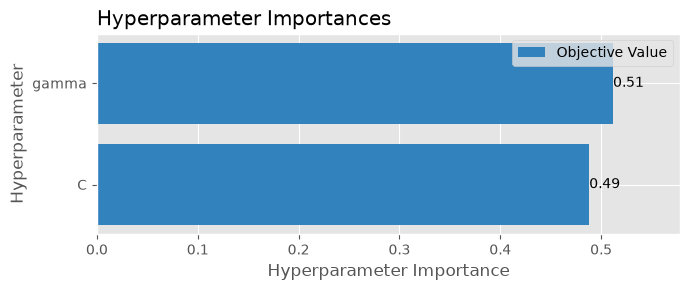

{'gamma': 0.5118120788849359, 'C': 0.4881879211150642}


In [15]:
ax = plot_param_importances(study)
ax.figure.set_size_inches(7, 3)
plt.tight_layout()
plt.show()

print(optuna.importance.get_param_importances(study))

### Hyperparameter and Feature Importance

| Importance | Asks | Computed from |
|:---|:---|:---|
| hyperparameter (Optuna) | which search knob changed the CV score? | the trials of a study |
| feature (model) | which input column changed the prediction? | one fitted model and its data |

- `permutation_importance` → shuffle one feature column and measure how much test accuracy drops; it reads the fitted model, it chooses nothing

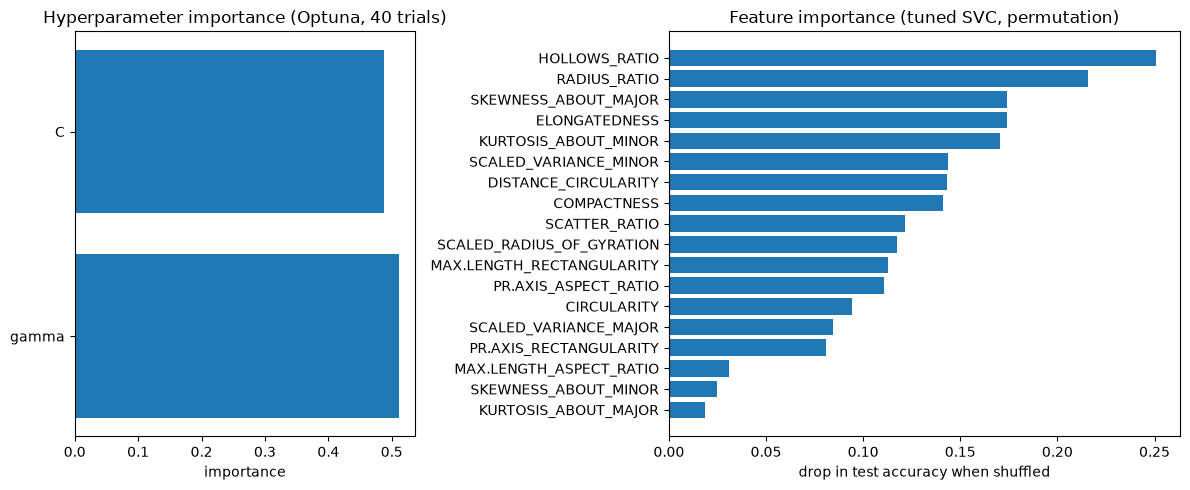

In [16]:
from sklearn.inspection import permutation_importance
plt.style.use('default')       # the Optuna plots switched matplotlib to the ggplot style

permutation = permutation_importance(model_optuna, X_test, y_test, n_repeats=20, random_state=42)
feature_importance = pd.Series(permutation.importances_mean, index=X_test.columns).sort_values()

param_importance = optuna.importance.get_param_importances(study)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), width_ratios=[1, 1.5])
axes[0].barh(list(param_importance.keys()), list(param_importance.values()))
axes[0].set_xlabel('importance')
axes[0].set_title('Hyperparameter importance (Optuna, 40 trials)')
axes[1].barh(feature_importance.index, feature_importance.values)
axes[1].set_xlabel('drop in test accuracy when shuffled')
axes[1].set_title('Feature importance (tuned SVC, permutation)')
plt.tight_layout()
plt.show()

- Left → both knobs mattered about equally (0.51 vs 0.49); right → shuffling `HOLLOWS_RATIO` alone costs about 25 points of test accuracy, the last few features under 5
- The two charts share the word *importance* and nothing else

---
# 4. The Model Family as a Parameter

- `suggest_categorical('family', [...])` → the model family is one more hyperparameter
- Its branch decides which hyperparameters are asked next → each family keeps its own names (`svc_C`, `logistic_C`)
- The same four families as the grid, 60 trials placed by Optuna instead of 20 candidates written in advance

In [17]:
def build_model_family(trial):                 # the family first, then only that family's hyperparameters
    family = trial.suggest_categorical(
        'family', ['LogisticRegression', 'KNeighborsClassifier', 'SVC', 'RandomForestClassifier'])

    if family == 'LogisticRegression':
        C = trial.suggest_float('logistic_C', 1e-2, 1e2, log=True)
        model = LogisticRegression(C=C, max_iter=2000, random_state=42)
    elif family == 'KNeighborsClassifier':
        n_neighbors = trial.suggest_int('knn_n_neighbors', 1, 15)
        model = KNeighborsClassifier(n_neighbors=n_neighbors)
    elif family == 'SVC':
        C = trial.suggest_float('svc_C', 1e-1, 1e3, log=True)
        gamma = trial.suggest_float('svc_gamma', 1e-4, 1e0, log=True)
        model = SVC(C=C, gamma=gamma, random_state=42)
    else:
        n_estimators = trial.suggest_int('rf_n_estimators', 50, 300, step=50)
        max_depth = trial.suggest_categorical('rf_max_depth', [None, 10, 20])
        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)

    return Pipeline([('scaler', StandardScaler()), ('model', model)])


def objective_family(trial):
    candidate = build_model_family(trial)
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, n_jobs=-1)
    return np.mean(scores)


study_family = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_family.optimize(objective_family, n_trials=60)
acc_val_optuna = study_family.best_value

print('trials     :', len(study_family.trials))
print('best params:', study_family.best_params)
print(f'best CV    : {acc_val_optuna:.4f}')

trials     : 60
best params: {'family': 'SVC', 'svc_C': 420.26281761141377, 'svc_gamma': 0.015270096624184128}
best CV    : 0.8565


- `best_params` is one flat dictionary → the prefixes keep `svc_C` and `logistic_C` apart
- The same family won as in the grid → SVC, with `C` = 420 from the wider range, CV 0.857; 40 of the 60 trials went to SVC once it pulled ahead

### Predicting with the Winner

- `FixedTrial(best_params)` again → `build_model_family` returns the winning pipeline, fitted here on the whole training set

In [18]:
model_optuna_family = build_model_family(optuna.trial.FixedTrial(study_family.best_params))
model_optuna_family.fit(X_train, y_train)

y_pred = model_optuna_family.predict(X_test)
acc_test_optuna = accuracy_score(y_test, y_pred)
print(f'test accuracy : {acc_test_optuna:.4f}')

test accuracy : 0.8706


---
# 5. The Whole Search — AutoGluon Tabular

- Only a table with a label column → AutoGluon preprocesses, trains its catalogue of model families with their defaults, validates, and **ensembles** the results
- Its validation → a 20 % holdout split from the training set, not our `cv`

Documentation: <https://auto.gluon.ai/stable/tutorials/tabular/tabular-essentials.html>

### What `fit()` Does

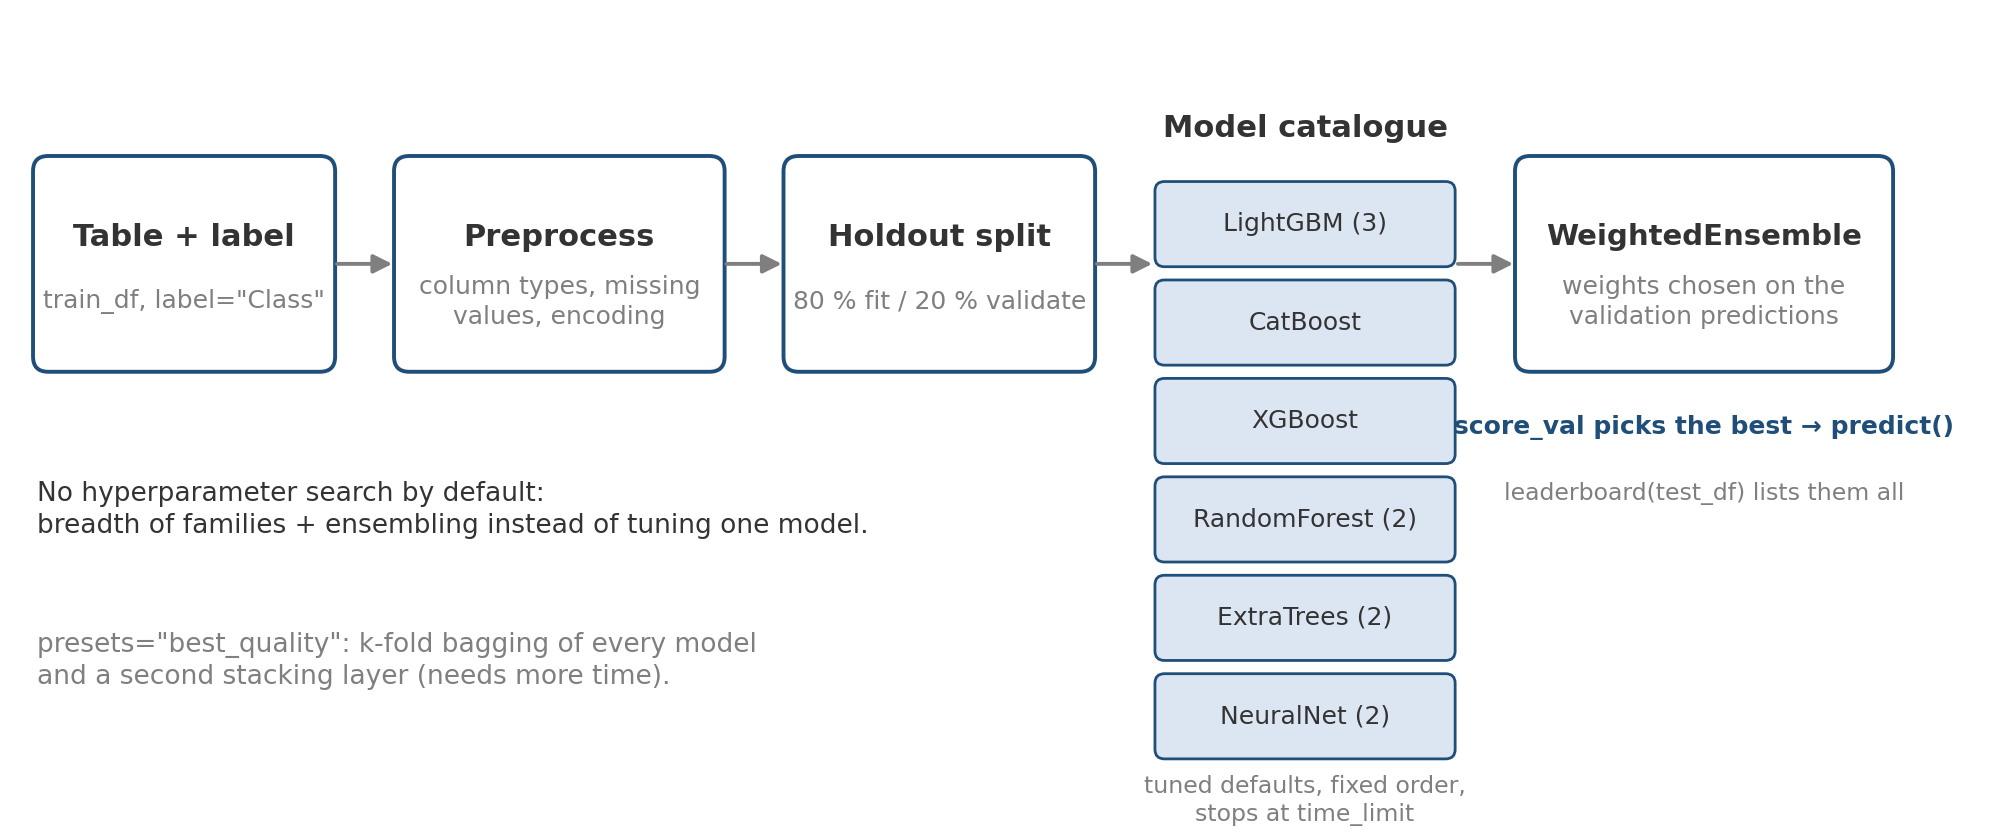

- Preprocess → 20 % holdout → a fixed catalogue of families, each with tuned defaults, in order, until `time_limit`
- A weighted ensemble on their validation predictions; `score_val` picks the model `predict()` uses
- No hyperparameter search by default → breadth and ensembling instead of tuning one model; `presets='best_quality'` adds bagging and stacking

In [19]:
train_df = X_train.copy()
train_df['Class'] = y_train
test_df = X_test.copy()
test_df['Class'] = y_test

train_df.head()

,COMPACTNESS,CIRCULARITY,DISTANCE_CIRCULARITY,RADIUS_RATIO,PR.AXIS_ASPECT_RATIO,MAX.LENGTH_ASPECT_RATIO,SCATTER_RATIO,ELONGATEDNESS,PR.AXIS_RECTANGULARITY,MAX.LENGTH_RECTANGULARITY,SCALED_VARIANCE_MAJOR,SCALED_VARIANCE_MINOR,SCALED_RADIUS_OF_GYRATION,SKEWNESS_ABOUT_MAJOR,SKEWNESS_ABOUT_MINOR,KURTOSIS_ABOUT_MAJOR,KURTOSIS_ABOUT_MINOR,HOLLOWS_RATIO,Class
200,93,47,85,163,66,11,156,44,20,158,172,355,178,74,7,15,183,195,van
396,108,57,106,177,51,5,256,26,28,170,285,966,261,87,11,2,182,181,bus
156,85,36,78,149,55,7,147,45,19,128,168,321,134,64,10,24,197,203,opel
86,89,41,84,141,58,9,149,45,19,145,172,330,162,72,4,18,188,200,van
635,97,41,62,133,56,7,130,52,18,143,158,247,157,78,5,7,184,186,van


In [20]:
from autogluon.tabular import TabularPredictor

predictor = TabularPredictor(label='Class', eval_metric='accuracy', verbosity=0)
predictor.fit(train_df, time_limit=120)

- `verbosity=0` keeps AutoGluon's own log quiet → the leaderboard below is the summary

### Leaderboard

- `leaderboard(test_df)` → every model it trained, with validation and test accuracy

In [21]:
leaderboard = predictor.leaderboard(test_df)
leaderboard[['model', 'score_test', 'score_val', 'stack_level']]

,model,score_test,score_val,stack_level
0,NeuralNetFastAI,0.823529,0.875000,1
1,WeightedEnsemble_L2,0.823529,0.875000,2
2,CatBoost,0.758824,0.786765,1
3,LightGBMXT,0.752941,0.830882,1
4,NeuralNetTorch,0.747059,0.808824,1
5,LightGBM,0.747059,0.779412,1
6,XGBoost,0.747059,0.786765,1
7,RandomForestEntr,0.735294,0.808824,1
8,ExtraTreesGini,0.735294,0.816176,1
9,ExtraTreesEntr,0.729412,0.808824,1


- `WeightedEnsemble_L2` → a weighted vote of the level-1 models, fitted on their validation predictions; `stack_level` 2 means it runs after them
- Here it scores exactly like `NeuralNetFastAI`, the strongest level-1 model → `score_val` chose it; `score_test` is the number to compare with the other sections

### Predicting with the Winner

- `predict(test_df)` → the best model by validation score, the ensemble

In [22]:
y_pred = predictor.predict(test_df)
acc_val_autogluon = leaderboard.set_index('model').loc[predictor.model_best, 'score_val']
acc_test_autogluon = accuracy_score(y_test, y_pred)
print('best model    :', predictor.model_best)
print(f'val accuracy  : {acc_val_autogluon:.4f}')
print(f'test accuracy : {acc_test_autogluon:.4f}')

best model    : WeightedEnsemble_L2
val accuracy  : 0.8750
test accuracy : 0.8235


### Another Model from the Leaderboard

- `predict(test_df, model=...)` → any row of the leaderboard; `set_model_best(name)` would make it the default

In [23]:
y_pred = predictor.predict(test_df, model='CatBoost')
print(f'CatBoost test accuracy : {accuracy_score(y_test, y_pred):.4f}')

CatBoost test accuracy : 0.7588


### AutoGluon Tuned

- The default preset trains each family once with its tuned defaults (about 12 of the 120 seconds here)
- `hyperparameter_tune_kwargs='auto'` → each family is searched over its built-in hyperparameter space, still inside `time_limit`; every trial becomes a leaderboard row (`\T1`, `\T2`, …)

In [24]:
predictor_tuned = TabularPredictor(label='Class', eval_metric='accuracy', verbosity=0)
predictor_tuned.fit(train_df, time_limit=120, hyperparameter_tune_kwargs='auto')

leaderboard_tuned = predictor_tuned.leaderboard(test_df)
leaderboard_tuned[['model', 'score_test', 'score_val', 'stack_level']].head(8)

,model,score_test,score_val,stack_level
0,NeuralNetFastAI\T20,0.847059,0.867647,1
1,NeuralNetFastAI\T7,0.835294,0.882353,1
2,NeuralNetFastAI\T1,0.823529,0.875000,1
3,NeuralNetFastAI\T16,0.823529,0.852941,1
4,NeuralNetFastAI\T13,0.817647,0.801471,1
5,NeuralNetFastAI\T19,0.811765,0.816176,1
6,NeuralNetTorch\T1,0.811765,0.911765,1
7,WeightedEnsemble_L2,0.811765,0.911765,2


In [25]:
y_pred = predictor_tuned.predict(test_df)
acc_val_autogluon_tuned = leaderboard_tuned.set_index('model').loc[predictor_tuned.model_best, 'score_val']
acc_test_autogluon_tuned = accuracy_score(y_test, y_pred)
print('best model    :', predictor_tuned.model_best)
print(f'val accuracy  : {acc_val_autogluon_tuned:.4f}')
print(f'test accuracy : {acc_test_autogluon_tuned:.4f}')

best model    : WeightedEnsemble_L2
val accuracy  : 0.9118
test accuracy : 0.8118


- Over a hundred trials in two minutes → the ensemble's validation score went up, its test accuracy did not → compared side by side in the next section

---
# 6. Comparison

- Same training set, same test set → each method's own validation score next to its test accuracy
- Validation = 5-fold CV on the training set for the two SVCs; AutoGluon's 20 % holdout (135 rows) for the two ensembles

In [26]:
comparison = pd.DataFrame({
    'validation': [acc_val_baseline, acc_val_optuna, acc_val_autogluon, acc_val_autogluon_tuned],
    'test':       [acc_test_baseline, acc_test_optuna, acc_test_autogluon, acc_test_autogluon_tuned]},
    index=['baseline SVC', 'Optuna best', 'AutoGluon ensemble', 'AutoGluon tuned'])
comparison.round(4)

,validation,test
baseline SVC,0.7441,0.7647
Optuna best,0.8565,0.8706
AutoGluon ensemble,0.8750,0.8235
AutoGluon tuned,0.9118,0.8118


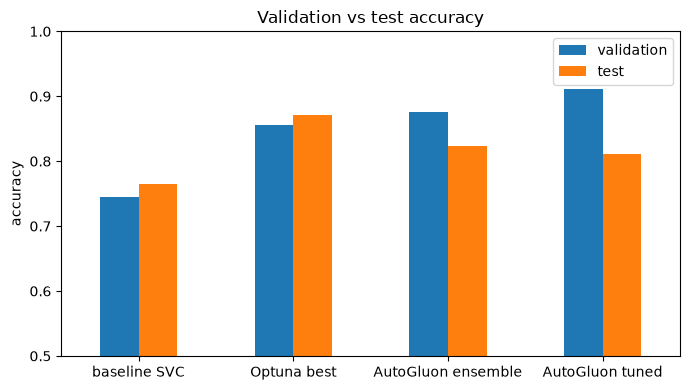

In [27]:
ax = comparison.plot.bar(figsize=(7, 4), rot=0, ylim=(0.5, 1.0))
ax.set_ylabel('accuracy')
ax.set_title('Validation vs test accuracy')
plt.tight_layout()
plt.show()

- Validation rises at every step; test follows for the tuned SVC but lags for AutoGluon → winners picked on a 135-row holdout, so part of the gain is noise and the tuned result varies by run
- AutoGluon has no SVM in its catalogue; its own remedy is bagging and stacking (`presets='best_quality'`), 0.859 here in 120 s
- What the tools decided differs → values, the family, or the whole pipeline; never the features, the split, the metric

---
## Summary

| | You write | It decides |
|:---|:---|:---|
| `GridSearchCV` | every candidate | nothing — it runs them all |
| Optuna | an objective function | which candidate to try next |
| AutoGluon | a table and a label | families, preprocessing, the ensemble |

- A higher validation score is not a better model when the validation set is small → the test set, used once at the end, settles it
- None of the tools chose the features, the split, or the problem → that part stayed ours